# Net worth over time

Reads the latest run file under `data/shared/state/runs/` and plots month-end net worth (nominal) plus an inflation-adjusted (CPI) series.

The run file is opened read-only via `RunConnection`; all reads go through `rc.items(...)`, which returns tidy DataFrames suitable for pandas groupby / pivot. See ADR-002 for the underlying schema.


In [13]:
from pathlib import Path

import pandas as pd

from analysis.sim.connection import RunConnection

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUNS_DIR = REPO / "data" / "shared" / "state" / "runs"

run_files = sorted(RUNS_DIR.glob("*.sqlite3"))
if not run_files:
    raise FileNotFoundError(f"no run files under {RUNS_DIR}")
RUN_FILE = run_files[-1]
print(f"latest run: {RUN_FILE.name}")

rc = RunConnection(RUN_FILE)


latest run: 2026-05-21T193104Z_current_46f6f10.sqlite3


In [14]:
_META_COLS = [
    "scenario_name", "status", "started_at", "finished_at",
    "code_version", "code_dirty", "data_version", "data_dirty",
    "data_mode", "run_by",
]
run_meta = rc.items("simulation_run")[_META_COLS].copy()
run_meta["code_version"] = run_meta["code_version"].str[:12]
run_meta["data_version"] = run_meta["data_version"].str[:12]
run_meta.T


,0
scenario_name,current
status,succeeded
started_at,2026-05-21T19:31:04Z
finished_at,2026-05-21T19:31:04Z
code_version,8532b29447fc
code_dirty,1
data_version,46f6f1028248
data_dirty,1
data_mode,live
run_by,rwk


In [15]:
nw = rc.items("net_worth").rename(columns={"net_worth": "nominal_cents"})
cpi = rc.items("net_worth_constant_cpi")[["month", "constant_cents"]]
nw = nw.merge(cpi, on="month", how="left")

nw["month"] = pd.to_datetime(nw["month"])
nw["nominal"] = nw["nominal_cents"] / 100
nw["cpi_constant"] = nw["constant_cents"].astype("Float64") / 100
nw = nw.set_index("month")
nw[["nominal", "cpi_constant"]].head()


,nominal,cpi_constant
month,,
2026-05-31,3743155.27,3733820.71
2026-06-30,3761930.20,3743191.78
2026-07-31,3780786.90,3752575.04
2026-08-31,3799725.73,3761970.59
2026-09-30,3818753.75,3771381.42


## Year-end net worth (table)


In [16]:
year_end = (
    nw.groupby(nw.index.year)
      .tail(1)
      .assign(year=lambda d: d.index.year)
      .set_index("year")[["nominal", "cpi_constant"]]
)
year_end.style.format({"nominal": "${:,.0f}", "cpi_constant": "${:,.0f}"})


,nominal,cpi_constant
year,,
2026,"$3,875,913","$3,799,271"
2027,"$4,042,810","$3,845,915"
2028,"$4,185,781","$3,864,406"
2029,"$4,338,536","$3,887,221"
2030,"$4,501,671","$3,914,347"
2031,"$4,675,824","$3,945,783"
2032,"$4,861,667","$3,981,530"
2033,"$5,059,918","$4,021,592"
2034,"$5,271,338","$4,065,978"


## Monthly net worth (chart)


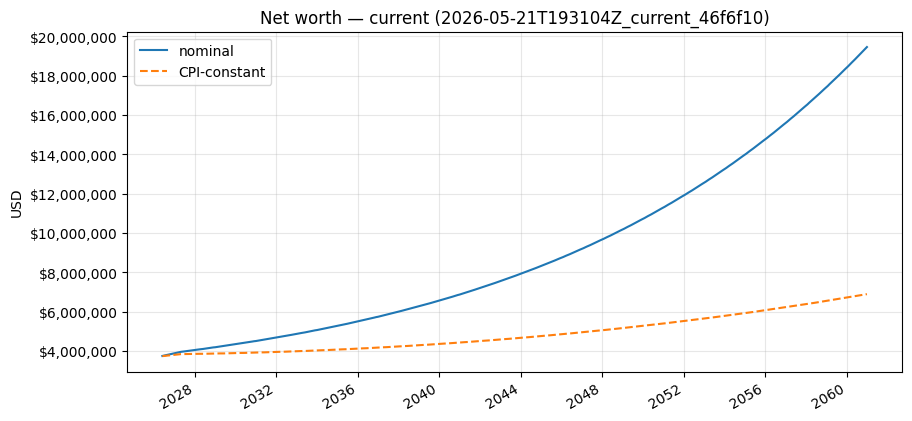

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nw.index, nw["nominal"], label="nominal")
if nw["cpi_constant"].notna().any():
    ax.plot(nw.index, nw["cpi_constant"], label="CPI-constant", linestyle="--")
ax.set_title(
    f"Net worth — {run_meta.loc[0, 'scenario_name']} "
    f"({RUN_FILE.stem})"
)
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.show()


## Income by category

Income flows are transfers _out of_ accounts with `kind = 'income'`. Subkinds are bucketed:

- **salary** — `salary`
- **investment** — `interest`, `dividend`, `capital_gain`
- **other** — `ss_benefit`, `pension`, `rental`, `other_income`


In [18]:
_INCOME_SUBKIND_TO_CAT = {
    "salary": "salary",
    "interest": "investment",
    "dividend": "investment",
    "capital_gain": "investment",
    "ss_benefit": "social security",
}
_INCOME_CATS = ["salary", "social security", "investment"]

xfer = rc.items("transfer_event", from_kind="income").copy()
xfer["month"] = pd.to_datetime(xfer["month"])
xfer["category"] = xfer["from_subkind"].map(_INCOME_SUBKIND_TO_CAT).fillna("other")

income = (
    xfer.groupby(["month", "category"])["amount"].sum()
        .unstack("category", fill_value=0)
        .reindex(columns=_INCOME_CATS, fill_value=0)
    / 100
)
income["total"] = income.sum(axis=1)
income.head()


category,salary,social security,investment,total
month,,,,
2026-05-31,10574.6,2825.0,9842.55,23242.15
2026-06-30,10574.6,2825.0,9923.93,23323.53
2026-07-31,10574.6,2825.0,10005.70,23405.30
2026-08-31,10574.6,2825.0,10087.83,23487.43
2026-09-30,10574.6,2825.0,10177.02,23576.62


In [19]:
_PRIOR_CAT = {
    "ss_benefit": "social security",
    "ordinary": "salary",
    "tax_free": "investment",
}
priors = rc.items("prior_tax_activity").assign(
    category=lambda d: d["bucket"].map(_PRIOR_CAT),
)
priors["amount"] = priors["amount"] / 100
priors_by_year = (
    priors.pivot_table(index="year", columns="category", values="amount",
                       aggfunc="sum", fill_value=0)
    .reindex(columns=_INCOME_CATS, fill_value=0)
)

income_yearly = income.groupby(income.index.year).sum()
income_yearly.index.name = "year"
# Fold priors into the same year totals (priors cover pre-sim YTD activity).
for cat in _INCOME_CATS:
    if cat in priors_by_year.columns:
        income_yearly[cat] = income_yearly[cat].add(
            priors_by_year[cat], fill_value=0,
        )
income_yearly["total"] = income_yearly[_INCOME_CATS].sum(axis=1)
income_yearly.style.format("${:,.0f}")


category,salary,social security,investment,total
year,,,,
2026,"$137,470","$33,900","$125,456","$296,826"
2027,"$47,586","$53,676","$131,818","$233,080"
2028,$0,"$67,802","$141,352","$209,154"
2029,$0,"$67,802","$151,135","$218,938"
2030,$0,"$67,802","$161,517","$229,319"
2031,$0,"$67,802","$172,533","$240,336"
2032,$0,"$67,802","$184,224","$252,027"
2033,$0,"$67,802","$196,632","$264,434"
2034,$0,"$67,802","$209,800","$277,602"


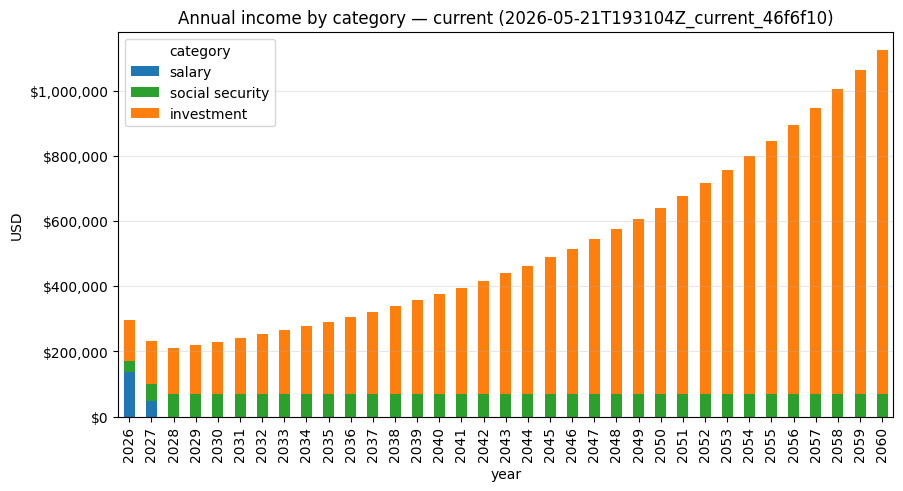

In [20]:
categories = ["salary", "social security", "investment"]
fig, ax = plt.subplots(figsize=(10, 5))
income_yearly[categories].plot(
    kind="bar", stacked=True, ax=ax,
    color=["#1f77b4", "#2ca02c", "#ff7f0e"],
)
ax.set_title(
    f"Annual income by category — {run_meta.loc[0, 'scenario_name']} "
    f"({RUN_FILE.stem})"
)
ax.set_xlabel("year")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(True, axis="y", alpha=0.3)
ax.legend(title="category")
plt.show()


## Expenses by category

Expense flows are transfers _into_ accounts with `kind = 'expense'`. Subkinds are bucketed:

- **housing** — `housing`, `interest_expense`
- **healthcare** — `healthcare`
- **taxes** — `taxes_federal`, `taxes_state`, `taxes_property`
- **living** — `living`
- **other** — `other_expense`


In [21]:
_EXPENSE_SUBKIND_TO_CAT = {
    "housing": "housing",
    "interest_expense": "housing",
    "taxes_property": "housing",
    "healthcare": "healthcare",
    "taxes_federal": "taxes",
    "taxes_state": "taxes",
    "living": "living",
    "food": "living",
}
_EXPENSE_CATS = ["housing", "healthcare", "taxes", "living", "other"]

xfer_exp = rc.items("transfer_event", to_kind="expense").copy()
xfer_exp["month"] = pd.to_datetime(xfer_exp["month"])
xfer_exp["category"] = (
    xfer_exp["to_subkind"].map(_EXPENSE_SUBKIND_TO_CAT).fillna("other")
)

expenses = (
    xfer_exp.groupby(["month", "category"])["amount"].sum()
        .unstack("category", fill_value=0)
        .reindex(columns=_EXPENSE_CATS, fill_value=0)
    / 100
)
expenses["total"] = expenses.sum(axis=1)
expenses_yearly = expenses.groupby(expenses.index.year).sum()
expenses_yearly.index.name = "year"
expenses_yearly.style.format("${:,.0f}")


category,housing,healthcare,taxes,living,other,total
year,,,,,,
2026,"$10,600","$15,454",$0,"$12,000","$4,134","$42,189"
2027,"$18,800","$23,181",$0,"$18,000","$6,202","$66,183"
2028,"$18,800","$23,181",$0,"$18,000","$6,202","$66,183"
2029,"$18,800","$23,181",$0,"$18,000","$6,202","$66,183"
2030,"$18,800","$23,181",$0,"$18,000","$6,202","$66,183"
2031,"$18,800","$23,181",$0,"$18,000","$6,202","$66,183"
2032,"$18,800","$23,181",$0,"$18,000","$6,202","$66,183"
2033,"$18,800","$23,181",$0,"$18,000","$6,202","$66,183"
2034,"$18,800","$23,181",$0,"$18,000","$6,202","$66,183"


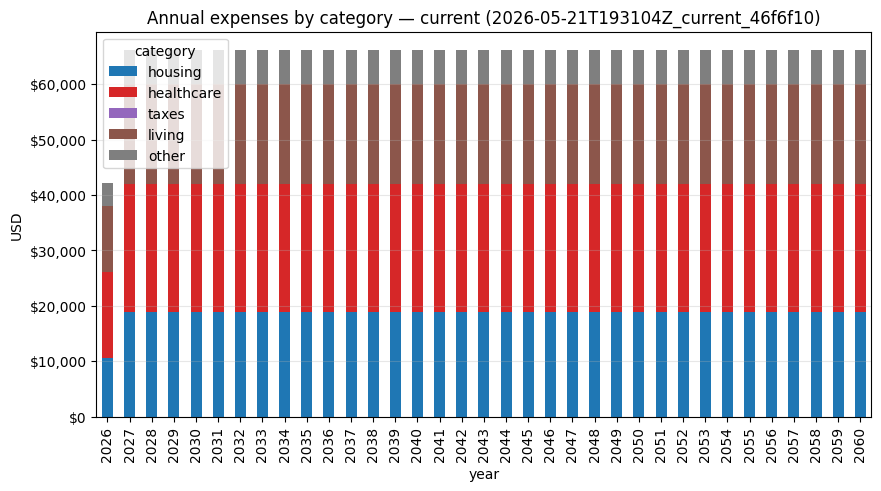

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
expenses_yearly[_EXPENSE_CATS].plot(
    kind="bar", stacked=True, ax=ax,
    color=["#1f77b4", "#d62728", "#9467bd", "#8c564b", "#7f7f7f"],
)
ax.set_title(
    f"Annual expenses by category — {run_meta.loc[0, 'scenario_name']} "
    f"({RUN_FILE.stem})"
)
ax.set_xlabel("year")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(True, axis="y", alpha=0.3)
ax.legend(title="category")
plt.show()


## Net income

Net income = total income (incl. prior-year tax activity) − total expenses, by year.


In [23]:
net = pd.DataFrame({
    "income": income_yearly["total"],
    "expenses": expenses_yearly["total"],
})
net["net"] = net["income"].fillna(0) - net["expenses"].fillna(0)
net.style.format("${:,.0f}")


,income,expenses,net
year,,,
2026,"$296,826","$42,189","$254,637"
2027,"$233,080","$66,183","$166,897"
2028,"$209,154","$66,183","$142,971"
2029,"$218,938","$66,183","$152,754"
2030,"$229,319","$66,183","$163,136"
2031,"$240,336","$66,183","$174,152"
2032,"$252,027","$66,183","$185,844"
2033,"$264,434","$66,183","$198,251"
2034,"$277,602","$66,183","$211,419"


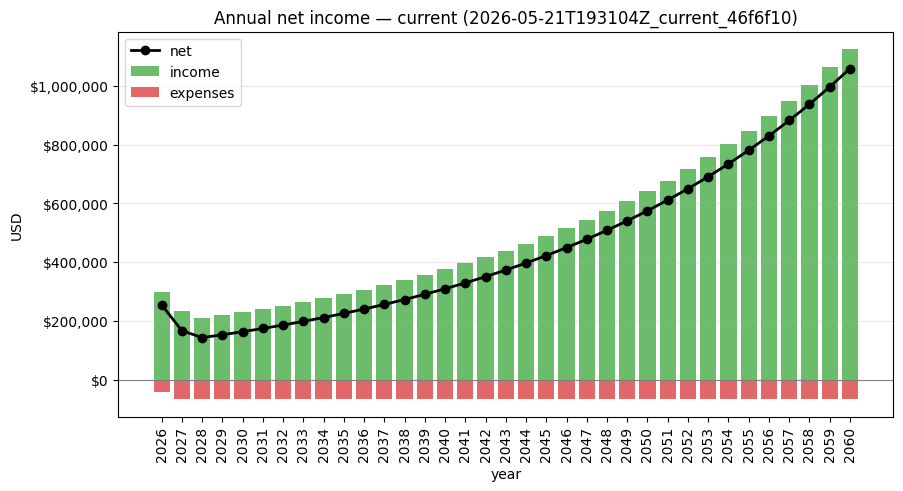

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
years = net.index.astype(str)
ax.bar(years, net["income"], label="income", color="#2ca02c", alpha=0.7)
ax.bar(years, -net["expenses"], label="expenses", color="#d62728", alpha=0.7)
ax.plot(years, net["net"], label="net", color="black", marker="o", linewidth=2)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_title(
    f"Annual net income — {run_meta.loc[0, 'scenario_name']} "
    f"({RUN_FILE.stem})"
)
ax.set_xlabel("year")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.setp(ax.get_xticklabels(), rotation=90)
plt.show()
